# P5: PyTorch and Policy Gradient Methods

> **Note: Machine learning for this assignment runs on your laptop's CPU and takes a while: 2–5 minutes per CartPole run (P5.2), 3–5 minutes for each of the three Pendulum training cells (P5.3), and 1–2 minutes per PPO run (P5.4). All told, it could take ~2 hours to run from scratch.**

In this assignment, you will be implementing your own approximate reinforcement learning methods. You will be using a few new packages: `torch` (the PyTorch package, focused on training deep learning algorithms), `gymnasium`, which implements a few classical control environments that we will be using to evaluate our RL algorithms, and `stable_baselines3` (in P5.4). Run the following to make sure they are installed:

In [7]:
# Check that the packages for this assignment are installed
import importlib.util

missing = [
    name
    for name in ["torch", "gymnasium", "pygame", "stable_baselines3", "pandas"]
    if importlib.util.find_spec(name) is None
]
if missing:
    raise ImportError(
        f"Missing: {', '.join(missing)}. Update your pyproject.toml to the latest course version and "
        "restart with `uv run launch-assignment-notebooks`"
    )
print("All packages are installed.")

All packages are installed.


In [8]:
## Starter Code
from IPython import display
import gymnasium as gym
import torch
from torch import nn
import numpy as np
import random
import matplotlib.pyplot as plt


def smooth_data(data, window_width=50):
    summed_data = np.cumsum(data)
    sm_data = (summed_data[window_width:] - summed_data[:-window_width]) / window_width
    return np.concatenate([np.zeros(window_width), sm_data])


def rollout(env, policy, epsilon, do_visualize=False):
    state, _ = env.reset()
    done = False
    data = []
    if do_visualize:
        img = plt.imshow(env.render())
    while not done:
        if do_visualize:
            img.set_data(env.render())
            display.display(plt.gcf())
            display.clear_output(wait=True)
        action = policy.sample_action(state, epsilon)
        try:
            new_state, reward, terminated, truncated, _ = env.step(action)
        except:
            new_state, reward, terminated, truncated, _ = env.step([action])
        done = terminated or truncated
        data.append((state, action, reward, new_state, done))
        state = new_state

    return data

## P5.1 Curve Fitting

As a starting point, we will go through some simple code to test your understanding of Gradient Descent to solve a curve fitting problem.

PyTorch, like most popular deep learning tools, supports "autodiff", a tool for automatically computing derivatives of many common functions used in neural networks, making it easy to perform gradient descent. PyTorch has built-in optimization tools as well, which we used to implement curve fitting in the example we did in class, reproduced here as a starting point for the remainder of this question.

**TASK** Run the "Curve Fitting Starter Code" below and confirm that your FitFunction approximates the data.

Step:      0  |    y = -0.799 + -1.464*x + -1.591*x^2 + 0.348*x^3  |  Loss: 317.0230407714844
Step:    250  |    y = 0.883 + -1.354*x + -0.219*x^2 + 0.391*x^3  |  Loss: 474.40057373046875
Step:    500  |    y = 2.035 + -1.389*x + 0.774*x^2 + 0.336*x^3  |  Loss: 3.336474657058716
Step:    750  |    y = 2.695 + -1.433*x + 1.351*x^2 + 0.289*x^3  |  Loss: 60.13859939575195
Step:   1000  |    y = 2.984 + -1.481*x + 1.670*x^2 + 0.273*x^3  |  Loss: 7.096201419830322
Step:   1250  |    y = 2.966 + -1.517*x + 1.792*x^2 + 0.263*x^3  |  Loss: 0.6218068599700928
Step:   1500  |    y = 2.825 + -1.546*x + 1.834*x^2 + 0.266*x^3  |  Loss: 0.025227684527635574
Step:   1750  |    y = 2.642 + -1.582*x + 1.857*x^2 + 0.274*x^3  |  Loss: 0.028706179931759834
Step:   2000  |    y = 2.453 + -1.613*x + 1.883*x^2 + 0.281*x^3  |  Loss: 0.030349401757121086
Step:   2250  |    y = 2.255 + -1.657*x + 1.896*x^2 + 0.278*x^3  |  Loss: 1.0888404846191406
Step:   2500  |    y = 2.075 + -1.697*x + 1.916*x^2 + 0.281*x^3  

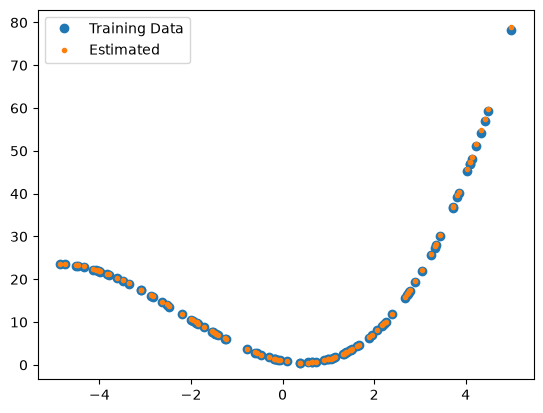

In [9]:
# Curve Fitting Starter Code [From the in-class example]

import numpy as np
import matplotlib.pyplot as plt
import torch


class FitFunction(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))

    def forward(self, x):
        return self.a + self.b * x + self.c * x**2 + self.d * x**3

    def string(self):
        return f"  y = {self.a.item():.3f} + {self.b.item():.3f}*x + {self.c.item():.3f}*x^2 + {self.d.item():.3f}*x^3"


def compute_loss(y, y_pred):
    return 0.5 * (y_pred - y) ** 2


# Generate some data from the curve we're trying to fit
xs = np.random.rand(100) * 10 - 5
ys = 1 - 2 * xs + 2 * (xs**2) + 0.3 * (xs**3)
plt.plot(xs, ys, "o")

# Instantiate the function with random guesses of the coefficients
model = FitFunction()

# Optimization loop
num_optim_steps = 20000
learning_rate = 1e-2
optim = torch.optim.Adam(model.parameters(), lr=learning_rate)

for t in range(num_optim_steps):
    # Get a random data point
    ind = np.random.randint(0, len(xs))
    y = ys[ind]

    # Make a prediction and compute the loss
    y_pred = model(xs[ind])
    loss = compute_loss(y, y_pred)

    # Debug print outputs
    if t % 250 == 0:
        print(f"Step: {t:6d}  |  " + model.string() + f"  |  Loss: {loss.item()}")

    # .backward() computes the gradient that the optimizer uses to train
    loss.backward()
    optim.step()
    optim.zero_grad()

# Compute the estimated values for all the data points (on training data...)
y_estimated = model(torch.tensor(xs)).detach().numpy()
plt.plot(xs, y_estimated, ".")
plt.gca().legend(["Training Data", "Estimated"])
None


### P5.1.1 Using an alternate update rule

We use the common "squared loss", equivalent to the "Mean Squared Error" used in linear algebra curve fitting problems. The loss is defined as follows:

$$\text{Loss} = \frac{1}{2}(y_\text{pred} - y) ^ 2 $$

In class, we discussed that the squared loss function gives rise to the following update rule (via gradient descent):

$$ \theta_\text{new} = \theta_\text{old} - \eta \nabla_\theta \text{Loss} \text{ [Update Rule \#1]}$$

$$ \theta_\text{new} = \theta_\text{old} - \eta (y_\text{pred} - y) \nabla_\theta y_\text{pred} \text{ [Update Rule \#2]}$$

where $\eta$ is the learning rate and $\nabla_\theta$ is the gradient with respect to the parameters $\theta$. Note that both rules are equivalent to one another. This can be easily derived from the chain rule, since $\nabla_\theta \frac{1}{2}(f(\theta) - a)^2 = (f(\theta) - a) \nabla_\theta f(\theta)$. You will show this equivalence in PyTorch by writing a new `compute_loss` function that matches [Update Rule #2].

In the RL scenarios in the questions below, you will want to be able to optimize scenarios that resemble [Update Rule #2]. As practice for this, your first task is to define a new `compute_loss_v2` function that looks like [Update Rule #2]. Note that using `loss = (y_pred - y) * y_pred` will *not* succeed, since both terms are differentiable with respect to the parameters $\theta$. To avoid this issue, you'll need to "detach" the terms for which you don't want to compute a gradient. There are two ways to do this in PyTorch:

```python

# _V1_
with torch.no_grad():
    # This is treated as a constant by PyTorch
    y_pred_constant = model(x)

# _V2_
# This is also treated as a constant by PyTorch
y_pred_constant = model(x).detach()
```

**TASK+CODE** Implement `compute_loss_v2`, which should rely on one of the two "detach" functions above. Note that the result you obtain in using this function should closely resemble the first version and the fit function should closely fit the data. You do not need to include the resulting plot in your writeup (but you should include your code!)

In [4]:
# Starter Code: compute loss
def compute_loss_v2(y, y_pred):
    # raise NotImplementedError()
    return (y_pred.detach() - y) * y_pred


Step:      0  |    y = 0.968 + -1.172*x + 0.952*x^2 + -0.117*x^3  |  Loss: -18.831497192382812
Step:    250  |    y = 1.875 + -0.885*x + 1.677*x^2 + 0.249*x^3  |  Loss: -58.41072463989258
Step:    500  |    y = 2.100 + -1.013*x + 1.897*x^2 + 0.256*x^3  |  Loss: -52.209022521972656
Step:    750  |    y = 1.996 + -1.131*x + 1.933*x^2 + 0.248*x^3  |  Loss: 28.388357162475586
Step:   1000  |    y = 1.833 + -1.243*x + 1.954*x^2 + 0.259*x^3  |  Loss: -0.9716277122497559
Step:   1250  |    y = 1.689 + -1.373*x + 1.966*x^2 + 0.263*x^3  |  Loss: -6.115424633026123
Step:   1500  |    y = 1.506 + -1.498*x + 1.966*x^2 + 0.271*x^3  |  Loss: 11.400790214538574
Step:   1750  |    y = 1.379 + -1.609*x + 1.985*x^2 + 0.277*x^3  |  Loss: 0.5323232412338257
Step:   2000  |    y = 1.292 + -1.699*x + 1.991*x^2 + 0.282*x^3  |  Loss: 4.513050556182861
Step:   2250  |    y = 1.207 + -1.777*x + 1.989*x^2 + 0.288*x^3  |  Loss: 10.538466453552246
Step:   2500  |    y = 1.116 + -1.852*x + 1.991*x^2 + 0.288*x^3  | 

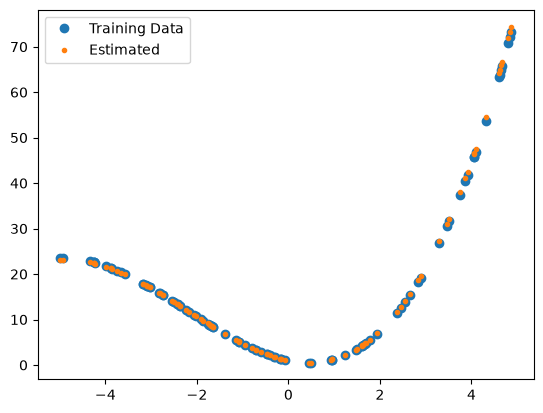

In [5]:
# Use the new loss function to train.

model = FitFunction()

# Optimization loop
num_optim_steps = 10000
learning_rate = 1e-2
optim = torch.optim.Adam(model.parameters(), lr=learning_rate)

for t in range(num_optim_steps):
    # Get a random data point
    ind = np.random.randint(0, len(xs))
    y = ys[ind]

    # Make a prediction and compute the loss
    y_pred = model(xs[ind])
    loss = compute_loss_v2(y, y_pred)

    # Debug print outputs
    if t % 250 == 0:
        print(f"Step: {t:6d}  |  " + model.string() + f"  |  Loss: {loss.item()}")

    # .backward() computes the gradient that the optimizer uses to train
    loss.backward()
    optim.step()
    optim.zero_grad()

# Compute the estimated values for all the data points (on training data...)
y_estimated = model(torch.tensor(xs)).detach().numpy()
plt.plot(xs, ys, "o")
plt.plot(xs, y_estimated, ".")
plt.gca().legend(["Training Data", "Estimated"])
None

### P5.1.2 Fitting to 2D data

I have provided you with some sample `2D` data that you should fit to using Gradient Descent.

**TASK** Complete `FitFunction2D` and write a script (using the 1D case as a starting point) that estimates the `zs` from the `xs` and `ys`.

**CODE** Include the resulting class definition and script in your writeup. If run, your code should nearly perfectly fit the data I have provided.

Step:      0  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 11552.13671875
Step:    250  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 2972.593017578125
Step:    500  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 46.057273864746094
Step:    750  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.029387300834059715
Step:   1000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.13393862545490265
Step:   1250  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 150.31666564941406
Step:   1500  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 7.252840995788574
Step:   1750  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 3960.47021484375
Step:   2000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 4575.5146484375


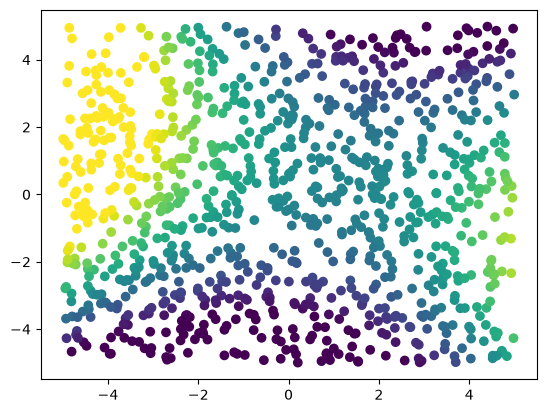

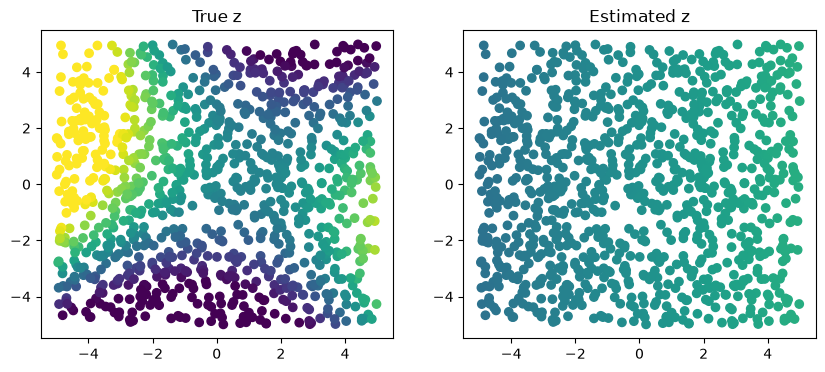

In [10]:
# Starter Code: 2D Data

# Generate some data from the curve we're trying to fit
xs = np.random.rand(1000) * 10 - 5
ys = np.random.rand(1000) * 10 - 5
zs = -1 - 2 * xs + 2 * ys + xs**2 - ys**2 - xs * ys

plt.figure()
plt.scatter(xs, ys, c=zs, vmin=-20, vmax=20)


class FitFunction2D(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # raise NotImplementedError()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))
        self.e = torch.nn.Parameter(torch.randn(()))
        self.f = torch.nn.Parameter(torch.randn(()))
        
    def forward(self, x, y):
        return (self.a + self.b * x + self.c * y + self.d * x**2 
                + self.e * y**2 + self.f * x * y)

    def string(self):
        return "Replace this if you wish! It's only for debugging/sanity checking"

# Instantiate the function with random guesses of the coefficients
model = FitFunction2D()

# Optimization loop
num_optim_steps = 20000
learning_rate = 1e-2
optim = torch.optim.Adam(model.parameters(), lr=learning_rate)

for t in range(num_optim_steps):
    # Get a random data point
    ind = np.random.randint(0, len(xs))
    z = zs[ind]

    # Make a prediction and compute the loss
    z_pred = model(zs[ind], ys[ind])
    loss = compute_loss(z, z_pred)

    # Debug print outputs
    if t % 250 == 0:
        print(f"Step: {t:6d}  |  " + model.string() + f"  |  Loss: {loss.item()}")

    # .backward() computes the gradient that the optimizer uses to train
    loss.backward()
    optim.step()
    optim.zero_grad()

# Compute the estimated values for all the data points (on training data...)
z_estimated = model(torch.tensor(xs), torch.tensor(ys)).detach().numpy()
print("Max abs error:", np.abs(z_estimated - zs).max())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(xs, ys, c=zs, vmin=-20, vmax=20); axes[0].set_title("True z")
axes[1].scatter(xs, ys, c=z_estimated, vmin=-20, vmax=20); axes[1].set_title("Estimated z")
None

## P5.2 Policy Learning in the CartPole Environment

In class we discussed the CartPole Environment, described and defined in detail here: https://gymnasium.farama.org/environments/classic_control/cart_pole/ . You will be using this environment to develop the three policy gradient algorithms we defined in lecture.

*Note: we use `CartPole-v1`, whose episodes end after 500 steps, so the maximum possible return is 500.*

### P5.2.1 Defining the Policy

Below, I have provided you with a partial implementation of the `PolicyApprox` function, which will take in the state of the environment and return a probability for each action. I have defined a simple neural network that ends with a "softmax" operation, ensuring that the output is normalized and so is a valid probability distribution.

**TASK+CODE** Complete the `sample_action` and `get_action_log_prob` functions in the partial implementation of the `PolicyApprox` class. Note that the `sample_action` function takes in a parameter `epsilon`, so that your policy is an epsilon-greedy "soft policy": epsilon percent of the time, the policy should pick a random action with uniform probability. The rest of the time, you should pick an action with a probability specified by the likelihoods output by the neural network. You may find `np.random.choice` a helpful function for this in your implementation. Include the completed functions in your writeup.

**TASK** Once you've completed the approximate policy class, run the "Results and Plotting" code below it a few times and observe the results.

**QUESTION** (2-4 sentences) Roughly how many steps does the typical trial manage before the pole falls to the side? Describe what behavior you should expect to keep the pendulum up.

In [11]:
## Policy Approximation Starter Code


class PolicyApprox(torch.nn.Module):
    def __init__(self, n_states, n_actions):
        super().__init__()
        # A single hidden layer neural network
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 32),
            nn.Tanh(),
            nn.Linear(32, n_actions),
            nn.Softmax(dim=-1),
        )

    def forward(self, state):
        return self.linear_relu_stack(torch.tensor(state, dtype=torch.float))

    def sample_action(self, state, epsilon=0.0):
        # Move data out of PyTorch and into numpy
        policy_outputs = self(state).detach().numpy()
        n_actions = len(policy_outputs)

        if np.random.rand() < epsilon:
            # Explore: uniform random action
            action = np.random.randint(n_actions)
        else:
            # Sample according to the policy's probabilities
            probs = policy_outputs.astype(np.float64)
            probs /= probs.sum()
            action = np.random.choice(n_actions, p=probs)
        # raise NotImplementedError()
        return action

    def get_action_log_prob(self, state, action):
        """Return the log of the probability associated with a particular action for a particular state."""
        # raise NotImplementedError()
        return torch.log(self(state)[action])

Num steps before failure: 19


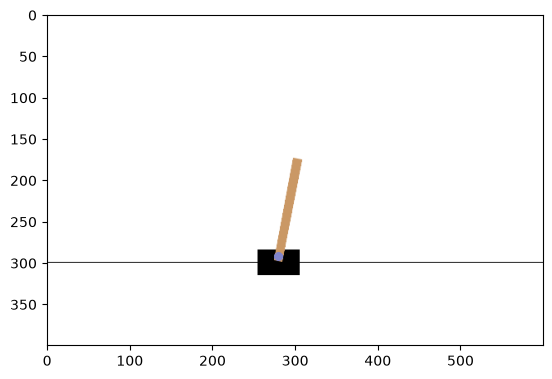

In [8]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)

rollout_data = rollout(env, policy, epsilon=0, do_visualize=True)

print(f"Num steps before failure: {len(rollout_data)}")

### P5.2.2 Implementing REINFORCE

In lecture, we discussed the REINFORCE algorithm, as presented in Chapter 13.3 in Sutton & Barto. Below, I have presented you with a partial implementation of REINFORCE.

**TASK+CODE** Complete the REINFORCE algorithm below using the lecture slides or Sutton & Barto as a reference. Include your definition of the loss function in your writeup. Note that to implement the algorithm, you may need to use what you learned in P5.1.1, so make sure you've done that question first.

**PLOTS** Run the Results & Plotting code using your newly-implemented REINFORCE implementation. Include the plot in your writeup.

**QUESTION** (2–4 sentences) Run the Results & Plotting code a few more times (3–5 times will be sufficient) and comment on the similarities and differences between the results and behavior of the system (e.g., how does the random initial configuration impact the performance of the system?)

**TASK+QUESTION+PLOT** (3–5 sentences) Increase the learning rate to `learning_rate=0.01` and run the results and plotting code a few more times. Include one of the plots in your writeup. How is the performance similar or different to the base configuration?

**TASK+QUESTION+PLOT** (3–5 sentences) Decrease the learning rate to `learning_rate=1e-4` and run the results and plotting code a few more times. Include one of the plots in your writeup. How is the performance similar or different to the base configuration?

In [19]:
# REINFORCE Starter Code


def reinforce(
    env, policy, num_episodes, learning_rate=0.01, gamma=0.95, epsilon0=0.1
):
    optim = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    all_rewards = []
    for ind in range(num_episodes):
        # Rollout
        rollout_data = rollout(env, policy, epsilon=epsilon0 / np.log10(ind + 2))

        G = 0
        loss = 0
        total_reward = 0
        for state, action, reward, new_state, done in reversed(rollout_data):
            total_reward += reward
            G = gamma * G + reward
            loss = loss - G * policy.get_action_log_prob(state, action)
            # loss = None
            # if loss is None:
                # raise NotImplementedError(
                #     "Implement the loss function (Sutton & Barto 13.3)"
                # )                    

        loss.backward()
        optim.step()
        optim.zero_grad()

        all_rewards.append(total_reward)
        if ind % 100 == 0:
            print(ind, total_reward, loss)

    return all_rewards

0 20.0 tensor(111.4319, grad_fn=<SubBackward0>)
100 70.0 tensor(586.1845, grad_fn=<SubBackward0>)
200 145.0 tensor(1376.3744, grad_fn=<SubBackward0>)
300 348.0 tensor(3776.0110, grad_fn=<SubBackward0>)
400 156.0 tensor(1701.9225, grad_fn=<SubBackward0>)
500 282.0 tensor(3148.2820, grad_fn=<SubBackward0>)
600 500.0 tensor(5588.5449, grad_fn=<SubBackward0>)
700 37.0 tensor(241.1618, grad_fn=<SubBackward0>)
800 145.0 tensor(1451.3197, grad_fn=<SubBackward0>)
900 168.0 tensor(1869.0494, grad_fn=<SubBackward0>)
1000 500.0 tensor(5545.0737, grad_fn=<SubBackward0>)
1100 228.0 tensor(2385.6147, grad_fn=<SubBackward0>)
1200 73.0 tensor(612.1572, grad_fn=<SubBackward0>)
1300 500.0 tensor(5486.4175, grad_fn=<SubBackward0>)
1400 378.0 tensor(4182.2305, grad_fn=<SubBackward0>)
1500 150.0 tensor(1519.1650, grad_fn=<SubBackward0>)
1600 62.0 tensor(473.2318, grad_fn=<SubBackward0>)
1700 24.0 tensor(117.2026, grad_fn=<SubBackward0>)
1800 112.0 tensor(956.0843, grad_fn=<SubBackward0>)
1900 61.0 tensor(4

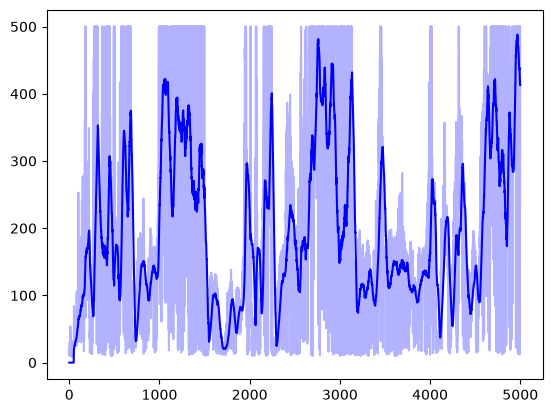

In [20]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)

REINFORCE_rewards = reinforce(env, policy, num_episodes=5000)
plt.figure()
plt.clf()
plt.plot(smooth_data(REINFORCE_rewards, window_width=50), "b")
plt.plot(REINFORCE_rewards, "b", alpha=0.3)
plt.show()

Num steps before failure: 476


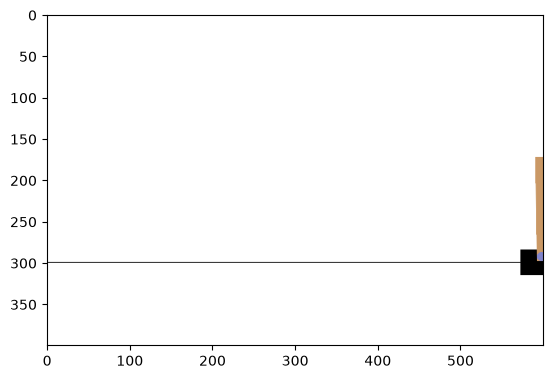

In [17]:
# Optional: See how your policy performed
rollout_data = rollout(env, policy, epsilon=0, do_visualize=True)
print(f"Num steps before failure: {len(rollout_data)}")

### P5.2.3 Implementing REINFORCE with Baseline

In lecture, we discussed the REINFORCE with Baseline algorithm, as presented in Chapter 13.4 in Sutton & Barto. This approach requires training both the policy function and also an estimator for the state value function V. I have provided you with a class `VApprox` that you should use for this purpose.

**TASK+CODE** Complete the REINFORCE with baseline algorithm below using the lecture slides or Sutton & Barto as a reference (and, of course, your code from P5.2.2). Include your implementation of REINFORCE with baseline in your writeup.

**PLOTS** Run the Results & Plotting code using your newly-implemented REINFORCE with Baseline implementation. Include the plot in your writeup.

**QUESTION** (2–4 sentences) Run the Results & Plotting code a few more times (3–5 times will be sufficient) and comment on the similarities and differences between the results and behavior of the system (e.g., how does the random initial configuration impact the performance of the system?)

**QUESTION** (3–5 sentences) How does the performance of REINFORCE with Baseline compare to the plain REINFORCE algorithm from P5.2.2? Comment on their relative performance. Which would you prefer to use and why?

[Feel free to use the rollout + visualization code to visualize your result]

In [13]:
# Starter Code: REINFORCE with Baseline


class VApprox(torch.nn.Module):
    def __init__(self, n_states):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, state):
        return 100 * self.linear_relu_stack(torch.tensor(state, dtype=torch.float))


def reinforce_with_baseline(
    env, policy, V, num_episodes, learning_rate=0.0005, gamma=0.95, epsilon0=0.1
):
    optim = torch.optim.Adam(policy.parameters(), lr=learning_rate)  # optim
    v_optim = torch.optim.Adam(V.parameters(), lr=learning_rate)  # optim
    all_rewards = []
    for ind in range(num_episodes):
        # raise NotImplementedError()
        rollout_data = rollout(env, policy, epsilon=epsilon0 / np.log10(ind + 2))

        G = 0
        loss = 0
        v_loss = 0
        total_reward = 0
        
        for state, action, reward, new_state, done in reversed(rollout_data):
            total_reward += reward
            G = gamma * G + reward

            v = V(state).squeeze()          # scalar tensor, has gradient w.r.t. V
            delta = G - v.detach()          # baseline-subtracted return (constant)

            # Policy (actor) loss: like REINFORCE, but with delta instead of G
            loss = loss - delta * policy.get_action_log_prob(state, action)
            # Value (baseline) loss: squared error between V(s) and the return
            v_loss = v_loss + 0.5 * (G - v) ** 2

        # Update the policy
        loss.backward()
        optim.step()
        optim.zero_grad()

        # Update the
        v_loss.backward()
        v_optim.step()
        v_optim.zero_grad()

        all_rewards.append(total_reward)

        if ind % 100 == 0:
            print(ind, total_reward, loss.item(), v_loss.item())

    return all_rewards

0 26.0 598.7138061523438 16540.3515625
100 15.0 2.7887096405029297 103.73584747314453
200 25.0 -24.078248977661133 182.18801879882812
300 51.0 35.95585250854492 781.3566284179688
400 49.0 -12.910053253173828 856.9519653320312
500 58.0 9.941793441772461 804.302734375
600 49.0 -11.002596855163574 612.3413696289062
700 53.0 -148.85256958007812 1420.84814453125
800 138.0 20.56876564025879 903.3783569335938
900 500.0 -12.785320281982422 578.8930053710938
1000 484.0 113.69953155517578 1122.7113037109375
1100 496.0 670.4756469726562 3625.127197265625
1200 311.0 118.39518737792969 858.1089477539062
1300 227.0 -41.85555648803711 1260.2030029296875
1400 369.0 117.53861999511719 1009.3613891601562
1500 442.0 49.9654655456543 390.1315002441406
1600 160.0 -33.92739486694336 947.9602661132812
1700 149.0 -156.251953125 716.1004638671875
1800 500.0 -163.9827880859375 1479.9072265625
1900 500.0 32.29793167114258 1596.982421875
2000 500.0 -10.0545015335083 1449.4949951171875
2100 290.0 55.53743743896484

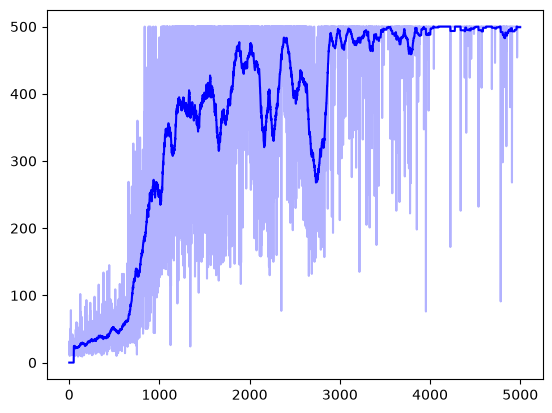

In [22]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)
V = VApprox(n_states=len(env.observation_space.low))

REINFORCE_with_baseline_rewards = reinforce_with_baseline(
    env, policy, V, num_episodes=5000
)

plt.figure()
plt.clf()
plt.plot(smooth_data(REINFORCE_with_baseline_rewards, window_width=50), "b")
plt.plot(REINFORCE_with_baseline_rewards, "b", alpha=0.3)
plt.show()

### P5.2.4 Implementing Actor-Critic

Finally, you'll implement the Actor-Critic algorithm, a TD-version of the REINFORCE with Baseline training strategy. Using what you've implemented so far, you will complete the `actor_critic` function below.

**TASK+CODE** Complete the Actor-Critic algorithm below using the lecture slides or Sutton & Barto as a reference (and, of course, your code from P5.2.3). Include your implementation in your writeup.

**PLOTS** Run the Results & Plotting code using your newly-implemented Actor-Critic implementation. Include the plot in your writeup.

**QUESTION** (2–4 sentences) Run the Results & Plotting code a few more times (3–5 times will be sufficient) and comment on the similarities and differences between the results and behavior of the system (e.g., how does the random initial configuration impact the performance of the system?)

[Feel free to use the rollout + visualization code from above to visualize your result]

In [1]:
# Actor Critic Starter Code


def actor_critic(
    env, policy, V, num_episodes, learning_rate=0.0005, gamma=0.95, epsilon0=0.1
):
    all_rewards = []
    optim = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    v_optim = torch.optim.Adam(V.parameters(), lr=learning_rate)

    for ind in range(num_episodes):
        epsilon = epsilon0 / np.log10(ind + 2)
        state, _ = env.reset()
        done = False
        I = 1.0  # gamma^t discount on the policy update (S&B 13.5)
        total_reward = 0

        while not done:
            action = policy.sample_action(state, epsilon)
            try:
                new_state, reward, terminated, truncated, _ = env.step(action)
            except:
                new_state, reward, terminated, truncated, _ = env.step([action])
            done = terminated or truncated
            total_reward += reward

            
            v_s = V(state)
            with torch.no_grad():
                v_next = 0.0 if terminated else V(new_state)
                delta = reward + gamma * v_next - v_s

            v_loss = -delta * v_s
            v_loss.backward()
            v_optim.step()
            v_optim.zero_grad()

            loss = -I * delta * policy.get_action_log_prob(state, action)
            loss.backward()
            optim.step()
            optim.zero_grad()

            I *= gamma
            state = new_state

        all_rewards.append(total_reward)
        if ind % 100 == 0:
            print(ind, total_reward, loss.item())

    return all_rewards


0 26.0 -3.138476848602295
100 16.0 -2.200566291809082
200 42.0 -2.4549319744110107
300 264.0 -8.750432607484981e-05
400 203.0 -2.3876491468399763e-05
500 210.0 -2.8567445042426698e-05
600 126.0 -2.282640934936353e-06
700 125.0 -0.0012234385358169675
800 155.0 -0.00010244832810712978
900 130.0 -2.3198314011096954e-05
1000 106.0 -6.872607173136203e-06
1100 120.0 2.329760536667891e-05
1200 108.0 0.023877739906311035
1300 98.0 0.0
1400 106.0 0.0
1500 109.0 -5.450136995932553e-06
1600 100.0 -2.2973517843638547e-06
1700 133.0 -0.00014573473890777677
1800 146.0 -0.00459102401509881
1900 222.0 -8.286145748570561e-05
2000 163.0 -5.038911695010029e-06
2100 122.0 -1.625222090240186e-08
2200 172.0 -1.8806815660354914e-06
2300 275.0 -9.945561174617978e-08
2400 156.0 3.54019612132106e-05
2500 179.0 -1.7729696992319077e-05
2600 104.0 -2.7200187105336227e-05
2700 182.0 -1.597358459548559e-05
2800 220.0 -3.011726423807204e-09
2900 27.0 -0.02563520334661007
3000 500.0 -1.0304907968605725e-14
3100 500.0 

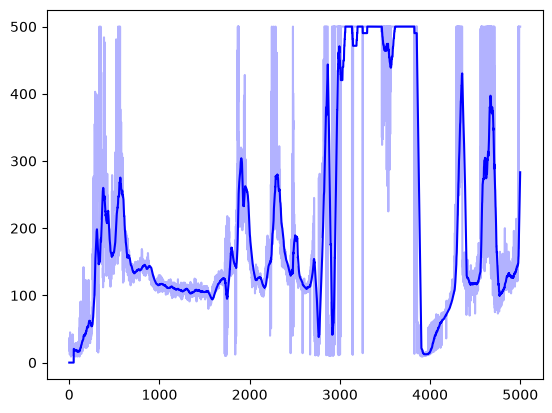

In [14]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)
V = VApprox(n_states=len(env.observation_space.low))

actor_critic_rewards = actor_critic(env, policy, V, num_episodes=5000)

plt.figure()
plt.clf()
plt.plot(smooth_data(actor_critic_rewards, window_width=50), "b")
plt.plot(actor_critic_rewards, "b", alpha=0.3)
plt.show()

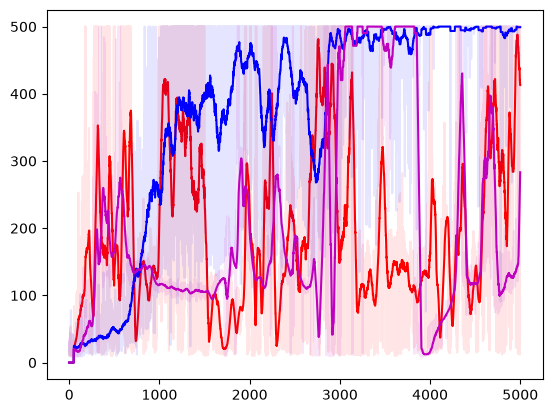

In [23]:
# Show all three on the same plot
plt.figure()
plt.clf()
rewards_list = [
    REINFORCE_rewards,
    REINFORCE_with_baseline_rewards,
    actor_critic_rewards,
]
for rewards, fmt in zip(rewards_list, ["r", "b", "m"]):
    plt.plot(rewards, fmt, alpha=0.1)
    plt.plot(smooth_data(rewards, window_width=50), fmt)
plt.show()

## P5.3 Continuous Action Policy Optimization

Next you will tackle a continuous action space, something for which policy gradient methods are well-suited. You have already implemented the training algorithms in P5.2! All that is left is to define the approximate policy function.

You will tackle the Pendulum environment, detailed here: https://gymnasium.farama.org/environments/classic_control/pendulum/

**TASK** Complete the `PolicyApproxGaussian` class. I have provided you with some starter code here. Note that the `forward` function returns a two-element tuple, that consists of the mean and standard deviation that will serve as inputs to the Normal/Gaussian distribution. The mean is scaled by `2 * tanh` to match the Pendulum's torque range of $[-2, 2]$, and `softplus` keeps the standard deviation positive. Fortunately, PyTorch has a number of built-in functions for this purpose, and defines everything you need to sample from a Gaussian distribution. Use the `torch.distributions` module [ documentation : https://pytorch.org/docs/stable/distributions.html ] to define the `sample_action` and `get_action_log_prob` functions in the partial implementation below. Note that this implementation is not epsilon-greedy, so don't worry about picking a "uniform random" action some percent of the time.

**CODE** Include your implementations of `sample_action` and `get_action_log_prob` in your writeup.

> **Note: each of the three training cells below takes about 3–5 minutes, and you will run them twice (for `g=2.0` and `g=5.0`).**

**PLOTS** Run the code below and include the resulting plots—showing the results for each approach on the Pendulum problem—in your writeup. If your policy code is set up properly, it should run without error. [In my experiments, the policy did fairly well much of the time, though not quite always; if you are confident in your implementation, running it again may yield better results. You can tune the parameters if you like, though I do not believe it will be necessary, and will take time (and sanity) you need not lose to 
this assignment.]

**TASK+PLOTS** Change the pendulum environment gravity parameter `g` to `5.0` (m/s^2) in the setup cell and rerun the results. Include the resulting three-curve plot in your writeup.

**QUESTION** (5–7 sentences) How does the performance change when you increase the gravity. Why? What does ideal behavior look like? Why is it so difficult to learn this behavior? Comment on what might be necessary to achieve better performance. *Note: you may need to look deeper into the pendulum environment or reason how you might solve this problem; you might also want to visualize your policy using the visualization code I have provided below.*

In [24]:
## Starter Code


class PolicyApproxGaussian(torch.nn.Module):
    def __init__(self, n_states):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 2),
        )

    def sample_action(self, state, epsilon=0.0):
        action_means, action_stddevs = self(state)
        action_stddevs = action_stddevs + 1e-6  # A trick to improve numerical stability
        if epsilon > 0.0:
            raise ValueError("No 'epsilon greedy' for this policy.")
        # raise NotImplementedError()
        # You may need to use action.numpy() if needed to move the action out of PyTorch
        with torch.no_grad():
            dist = torch.distributions.Normal(action_means, action_stddevs)
            action = dist.sample()

        return action.numpy()

    def get_action_log_prob(self, state, action):
        action_means, action_stddevs = self(state)
        action_stddevs = action_stddevs + 1e-6  # A trick to improve numerical stability
        # Note: It's important that you *don't* use .numpy() or .detach() here!
        # That gradient is how training works!
        # raise NotImplementedError()
        dist = torch.distributions.Normal(action_means, action_stddevs)
        return dist.log_prob(torch.as_tensor(action, dtype=torch.float))


    def forward(self, state):
        output = self.linear_relu_stack(torch.tensor(state, dtype=torch.float))
        return 2 * torch.tanh(output[0]), nn.functional.softplus(output[1])

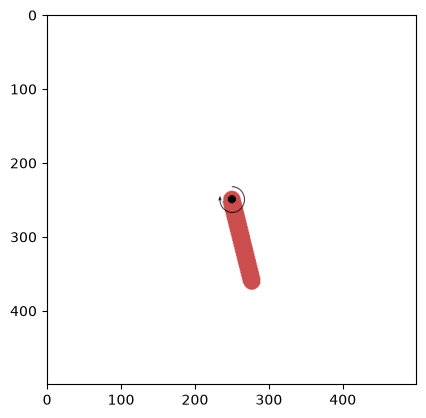

In [25]:
# Visualization Code (random policy)

env_cont = gym.make("Pendulum-v1", g=2.0, render_mode="rgb_array")
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
rollout_data = rollout(env_cont, policy, epsilon=0, do_visualize=True)

In [32]:
# Results and Plotting: setup (change g here for the g=5.0 question)

# I have provided you with a slightly different V function.
# I found it to work better for the Pendulum example.


class VApproxDeeper(torch.nn.Module):
    def __init__(self, n_states):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 1),
        )

    def forward(self, state):
        return 100 * self.linear_relu_stack(torch.tensor(state, dtype=torch.float))


env_cont = gym.make("Pendulum-v1", g=5.0, render_mode="rgb_array")

In [33]:
# Results and Plotting: REINFORCE (takes about 3-5 minutes)
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
REINFORCE_rewards = reinforce(
    env_cont, policy, num_episodes=5000, learning_rate=0.001, gamma=0.98, epsilon0=0.0
)

0 -1487.7167306452666 tensor(-63910.2188, grad_fn=<SubBackward0>)
100 -1108.17859040995 tensor(-44470.4922, grad_fn=<SubBackward0>)
200 -822.7692737091099 tensor(-29751.6973, grad_fn=<SubBackward0>)
300 -1285.9770530364985 tensor(-58168.5820, grad_fn=<SubBackward0>)
400 -1365.2743092756564 tensor(-61751.7891, grad_fn=<SubBackward0>)
500 -1396.2584086232996 tensor(-70923.3906, grad_fn=<SubBackward0>)
600 -969.4169247992979 tensor(-46490.8477, grad_fn=<SubBackward0>)
700 -1322.2109531856381 tensor(-71174.2109, grad_fn=<SubBackward0>)
800 -1602.3315495181055 tensor(-83466.0547, grad_fn=<SubBackward0>)
900 -1493.9686812559623 tensor(-81722.2891, grad_fn=<SubBackward0>)
1000 -947.9143030038043 tensor(-53857.1289, grad_fn=<SubBackward0>)
1100 -1216.1078949762395 tensor(-37180.7383, grad_fn=<SubBackward0>)
1200 -834.7138802131794 tensor(-34764.5820, grad_fn=<SubBackward0>)
1300 -1619.0054003923065 tensor(-83273.4922, grad_fn=<SubBackward0>)
1400 -1297.1781433043695 tensor(-59033.2344, grad_fn

In [34]:
# Results and Plotting: REINFORCE with Baseline (takes about 3-5 minutes)
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
V = VApproxDeeper(n_states=len(env_cont.observation_space.low))
REINFORCE_baseline_rewards = reinforce_with_baseline(
    env_cont,
    policy,
    V,
    num_episodes=5000,
    learning_rate=0.001,
    gamma=0.98,
    epsilon0=0.0,
)

0 -1465.3106829702335 -59223.28515625 9243268.0
100 -1713.8307070758858 -25818.30859375 3413399.75
200 -1417.2882226737022 -8582.9453125 1179437.5
300 -1446.964280480808 -4365.0810546875 995827.125
400 -1098.0154354175572 -2756.970703125 416390.375
500 -1302.1248998850554 -7813.681640625 1063133.125
600 -927.6601512350821 6341.5234375 433737.375
700 -923.4877004181357 2292.882568359375 233737.4375
800 -1115.2314410634674 994.6066284179688 521385.1875
900 -806.4524633985611 -1417.972900390625 222117.671875
1000 -691.6112790568501 7569.47216796875 302531.4375
1100 -1452.8938647984214 -5917.4755859375 817020.125
1200 -1145.3391665316974 2305.392578125 337334.0625
1300 -820.9905224336371 -4722.59033203125 511796.5625
1400 -866.6194690196203 -11589.98046875 587633.6875
1500 -727.8140238128783 2213.09619140625 168242.734375
1600 -1611.0211916339804 -2315.059814453125 1163715.75
1700 -1535.992053209069 7683.22900390625 856647.3125
1800 -1273.159084031408 -50.10132598876953 611481.0
1900 -938.

In [35]:
# Results and Plotting: Actor-Critic (takes about 3-5 minutes)
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
V = VApproxDeeper(n_states=len(env_cont.observation_space.low))
actor_critic_rewards = actor_critic(
    env_cont,
    policy,
    V,
    num_episodes=5000,
    learning_rate=0.001,
    gamma=0.98,
    epsilon0=0.0,
)

0 -1671.7629918739342 -0.024025456979870796
100 -982.9412128558928 0.013515723869204521
200 -0.10047372410248817 -0.00021449252380989492
300 -22.85709788139384 0.0006975545547902584
400 -20.33213612188201 -4.336565689300187e-05
500 -1498.2348573282452 -0.05469870939850807
600 -946.8420048134883 -0.0036678770557045937
700 -21.7686975107809 0.004563784226775169
800 -913.0954491889669 -0.01032990962266922
900 -971.6760397108393 -0.14189667999744415
1000 -1682.7103792215248 0.03277679160237312
1100 -969.9734454454887 -0.024425208568572998
1200 -877.5217584771601 0.008306033909320831
1300 -966.6473085714249 -0.014818130992352962
1400 -677.6461926930051 -0.008164292201399803
1500 -981.3670825784274 0.01934686303138733
1600 -996.6672535102626 0.005275311879813671
1700 -1452.4549545480868 0.06458475440740585
1800 -1770.7524396298152 0.07991581410169601
1900 -1316.871223298128 0.5576953291893005
2000 -1325.336958733641 0.07178910821676254
2100 -924.7819401052656 -0.1293000727891922
2200 -1537.9

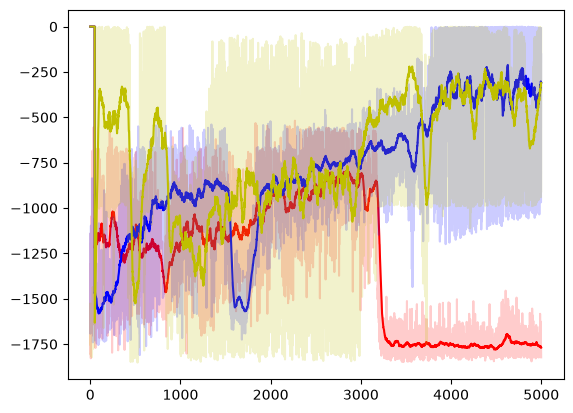

In [36]:
# Show all three on the same plot
plt.figure()
plt.clf()
rewards_list = [REINFORCE_rewards, REINFORCE_baseline_rewards, actor_critic_rewards]
for rewards, fmt in zip(rewards_list, ["r", "b", "y"]):
    plt.plot(rewards, fmt, alpha=0.2)
    plt.plot(smooth_data(rewards, window_width=50), fmt)
plt.show()

Num steps before failure: 200


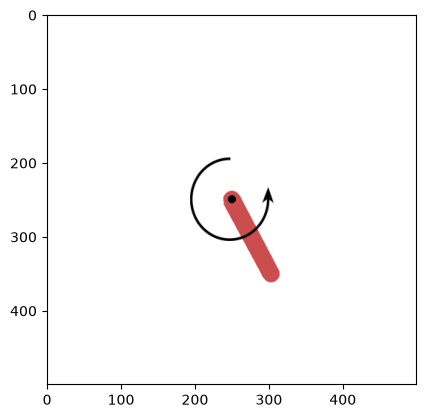

In [37]:
# Visualization
rollout_data = rollout(env_cont, policy, epsilon=0, do_visualize=True)
print(f"Num steps before failure: {len(rollout_data)}")

## P5.4 Running PPO

While I do not want you to *implement* PPO, I did want you to play around with it a bit. I have found a package that implements PPO and some utilities for fast training, data logging, etc. You'll use this instead for this final question.

**TASK** Run the training and evaluation code that follows for `gravity = 2.0` and `gravity = 5.0` and `gravity = 9.81`. Run the code a few times to see how performance varies with random seed.

**PLOTS** When run, the code will generate "monitor.csv" files in the local folder `PPO_monitor_outs` that the code below reads in and plots. Include plots for each value of gravity.

**QUESTION** (3–4 sentences) How quickly does the system learn as a function of the gravity parameter. Comment on how this is or is not consistent with your results from your own implementation?

Using cpu device
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.26e+03 |
| time/              |           |
|    fps             | 3598      |
|    iterations      | 1         |
|    time_elapsed    | 2         |
|    total_timesteps | 8192      |
----------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 200          |
|    ep_rew_mean          | -1.23e+03    |
| time/                   |              |
|    fps                  | 2593         |
|    iterations           | 2            |
|    time_elapsed         | 6            |
|    total_timesteps      | 16384        |
| train/                  |              |
|    approx_kl            | 0.0018291275 |
|    clip_fraction        | 0.0105       |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.42        |
|    explained_variance   | -0.

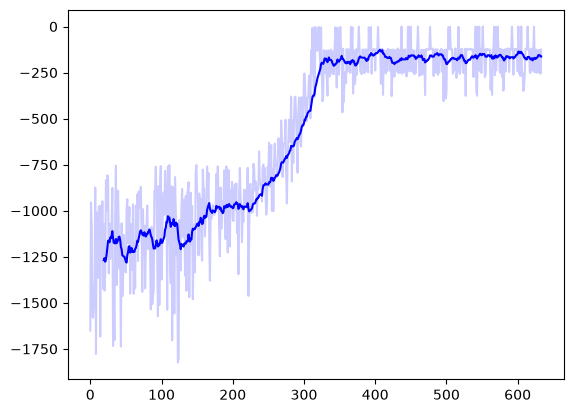

In [40]:
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
import pandas as pd

gravity = 9.81
env_cont = gym.make("Pendulum-v1", g=gravity, render_mode="rgb_array")

# Parallel environments
vec_env = make_vec_env(
    "Pendulum-v1", n_envs=4, env_kwargs={"g": gravity}, monitor_dir="PPO_monitor_outs"
)
model = PPO("MlpPolicy", vec_env, verbose=1).learn(500000)

results_df = pd.read_csv("PPO_monitor_outs/0.monitor.csv", header=1)
plt.figure()
plt.plot(results_df["r"], "b", alpha=0.2)
plt.plot(results_df.rolling(20).mean()["r"], "b")
plt.show()